In [39]:
import joblib
import numpy as np
from model.dataset import vectorize_state, rank_to_elo
import os
import json
from scipy import stats
from model.network import Network
import torch
import seaborn as sns
from model.game import create_initial_state, update_with_event, sync_timers
import copy
from tqdm import tqdm

In [40]:
with open('item.json') as f:
    item_data = json.load(f)

In [41]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ckpt = torch.load('gru_best.pt', map_location=device)

In [42]:
def is_strong_event(event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['killerId'] == 0:
        return False
    return event['type'] in ['CHAMPION_KILL', 'BUILDING_KILL', 'ELITE_MONSTER_KILL']

def sample_history_before(game, callback, rank):
    state = create_initial_state(game)
    features = []
    prev_sampled_t = 0.0
    prev_event_t = 0.0
    rank_elo = rank_to_elo(rank)

    for i, event in enumerate(game['events']):
        t = event['timestamp']
        delta = t - prev_event_t

        matched, outcome = callback(state, event)
        strong = is_strong_event(event)

        if strong or matched:
            state_copy = copy.deepcopy(state)
            sync_timers(state_copy, delta)
            state_copy['time'] = t

            v = vectorize_state(state_copy)
            v.append(rank_elo)
            v.append((t - prev_sampled_t) / 60_000.0)
            features.append(v)
            prev_sampled_t = t

            if matched:
                return features, outcome

        update_with_event(state, event, delta)
        prev_event_t = t

    return None, None


def sample_all_matching(game, callback, rank):
    state = create_initial_state(game)
    features = []
    matches = []
    prev_sampled_t = 0.0
    prev_event_t = 0.0
    rank_elo = rank_to_elo(rank)

    for i, event in enumerate(game['events']):
        t = event['timestamp']
        delta = t - prev_event_t

        matched, outcome = callback(state, event)
        strong = is_strong_event(event)

        if strong or matched:
            state_copy = copy.deepcopy(state)
            sync_timers(state_copy, delta)
            state_copy['time'] = t

            v = vectorize_state(state_copy)
            v.append(rank_elo)
            v.append((t - prev_sampled_t) / 60_000.0)
            features.append(v)
            prev_sampled_t = t

            if matched:
                matches.append((len(features) - 1, outcome))

        update_with_event(state, event, delta)
        prev_event_t = t

    return features, matches

In [43]:
root = 'dataset/test'

all_files = []

for dirpath, dirnames, filenames in os.walk(root):
    for filename in filenames:
        all_files.append(os.path.join(dirpath, filename))

In [44]:
lengths = []

for fn in all_files:
    if fn[-5:] == 'Store':
        continue
    with open(fn, encoding='utf-8') as f:
        game = json.load(f)
        events = filter(is_strong_event, game['events'])
        lengths.append(len(list(events)))

In [45]:
len(lengths)

140810

<Axes: ylabel='Count'>

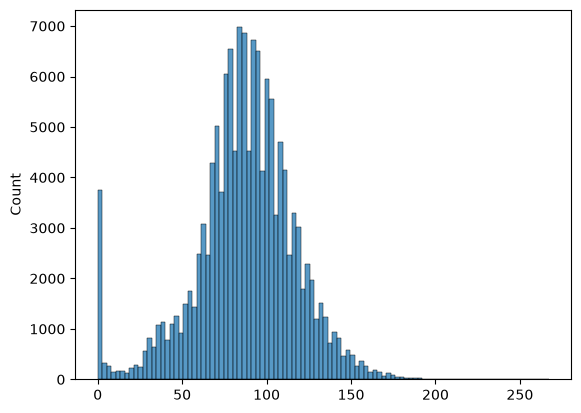

In [46]:
sns.histplot(data=lengths, bins=100)

In [47]:
np.mean(lengths).item()

87.17892195156594

In [48]:
np.std(lengths).item()

30.347906253390498

In [49]:
model = Network(
    n_numerical=ckpt['means'].shape[0],
    means=ckpt['means'],
    stds=ckpt['stds'],
    n_champions=173,
    emb_dim=ckpt['embed.weight'].shape[1],
    hidden_dim=ckpt['rnn.weight_hh_l0'].shape[1],
    num_layers=sum(1 for k in ckpt if k.startswith('rnn.weight_ih_l')),
    dropout=0.0,
).to(device)
model.load_state_dict(ckpt)
model.eval()

Network(
  (embed): Embedding(173, 4)
  (rnn): GRU(203, 64, num_layers=2, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [50]:
def format_wpa_summary(mean, me):
    def format_percentage(number):
        return f'{round(number * 100, 2)}%'

    return f'{format_percentage(mean)} ± {format_percentage(me)}'

In [51]:
def predict_blue_win_prob(features):
    """Model's P(blue wins) at the last timestep of `features`."""
    x = torch.tensor(np.array(features, dtype=np.float32), device=device).unsqueeze(0)
    lengths = torch.tensor([len(features)], dtype=torch.long)
    with torch.no_grad():
        probs = model(x, lengths)
    return probs[0, -1].item()

In [52]:
def calc_first_event_wpa(callback):
    """WPA at the first matching event per game."""
    winrates, wpes = [], []

    pbar = tqdm(all_files, desc='calc_first_event_wpa', leave=True)
    for game_path in pbar:
        if '.DS_Store' in game_path:
            continue
        rank = game_path.split('/')[2]
        with open(game_path) as f:
            game = json.load(f)

        features, outcome = sample_history_before(game, callback, rank)
        if features is None:
            continue

        winrates.append(game['win'] == outcome)
        prob_blue = predict_blue_win_prob(features)
        wpes.append(prob_blue if outcome == 1 else 1 - prob_blue)

        pbar.set_postfix(matches=len(winrates))

    return np.array(winrates), np.array(wpes)

In [53]:
def calc_average_event_wpa(callback):
    """WPA at every matching event per game."""
    winrates, wpes = [], []

    pbar = tqdm(all_files, desc='calc_average_event_wpa', leave=True)
    for game_path in pbar:
        if '.DS_Store' in game_path:
            continue
        rank = game_path.split('/')[2]
        with open(game_path) as f:
            game = json.load(f)

        features, matches = sample_all_matching(game, callback, rank)
        for sample_idx, outcome in matches:
            prefix = features[:sample_idx + 1]
            winrates.append(game['win'] == outcome)

            prob_blue = predict_blue_win_prob(prefix)
            wpes.append(prob_blue if outcome == 1 else 1 - prob_blue)

        pbar.set_postfix(matches=len(winrates))

    return np.array(winrates), np.array(wpes)

In [54]:
def calculate_wpa_ci(wr, we):
    d = wr - we
    n = len(d)
    mean = d.mean()
    std = d.std(ddof=1)
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    me = t_value * sem
    return mean, me

In [55]:
def get_item_callback(item_id):
    def item_callback(state, event):
        if event['type'] == 'ITEM_PURCHASED' and event['itemId'] == item_id:
            return True, 1 - int((event['participantId'] - 1) / 5)
        return False, None

    return item_callback

In [26]:
def champion_kill(state, event):
    if event['type'] == 'CHAMPION_KILL':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [57]:
def baron(state, event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['monsterType'] == 'BARON_NASHOR':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [58]:
def elder(state, event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['monsterType'] == 'DRAGON' and event['monsterSubType'] == 'ELDER_DRAGON':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [59]:
def dragon(state, event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['monsterType'] == 'DRAGON' and event['monsterSubType'] != 'ELDER_DRAGON':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [60]:
def void_grubs(state, event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['monsterType'] == 'HORDE':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [61]:
def riftherald(state, event):
    if event['type'] == 'ELITE_MONSTER_KILL' and event['monsterType'] == 'RIFTHERALD':
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [62]:
def top_tower(state, event):
    if event['type'] == 'BUILDING_KILL' and event['buildingType'] == 'TOWER_BUILDING' and event['laneType'] == 'TOP_LANE' and event['killerId'] != 0 and sum(state['teams'][0]['towers']) == 9 and sum(state['teams'][1]['towers']) == 9:
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [63]:
def mid_tower(state, event):
    if event['type'] == 'BUILDING_KILL' and event['buildingType'] == 'TOWER_BUILDING' and event['laneType'] == 'MID_LANE' and event['killerId'] != 0 and sum(state['teams'][0]['towers']) == 9 and sum(state['teams'][1]['towers']) == 9:
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [64]:
def bot_tower(state, event):
    if event['type'] == 'BUILDING_KILL' and event['buildingType'] == 'TOWER_BUILDING' and event['laneType'] == 'BOT_LANE' and event['killerId'] != 0 and sum(state['teams'][0]['towers']) == 9 and sum(state['teams'][1]['towers']) == 9:
        return True, 1 - int((event['killerId'] - 1) / 5)
    return False, None

In [56]:
def kayn_transform_blue(state, event):
    if event['type'] == 'CHAMPION_TRANSFORM' and event['transformType'] == 'ASSASSIN':
        return True, 1 - int((event['participantId'] - 1) / 5)
    return False, None

In [57]:
def kayn_transform_red(state, event):
    if event['type'] == 'CHAMPION_TRANSFORM' and event['transformType'] == 'SLAYER':
        return True, 1 - int((event['participantId'] - 1) / 5)
    return False, None

In [19]:
item_ids = [3363, 3157, 3916, 3165]

for item_id in item_ids:
    wr, we = calc_average_event_wpa(get_item_callback(item_id))
    mean, me = calculate_wpa_ci(wr, we)
    item_name = item_data['data'][str(item_id)]['name']
    print(f'{item_name}: ' + format_wpa_summary(mean, me))

Farsight Alteration: nan% ± nan%
Zhonya's Hourglass: nan% ± nan%
Oblivion Orb: nan% ± nan%
Morellonomicon: nan% ± nan%


/tmp/ipykernel_46478/3091195261.py:4: RuntimeWarning: Mean of empty slice
  mean = d.mean()
/home/fahd/.pyenv/versions/3.12.2/envs/lolenv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/fahd/.pyenv/versions/3.12.2/envs/lolenv/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/fahd/.pyenv/versions/3.12.2/envs/lolenv/lib/python3.12/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/fahd/.pyenv/versions/3.12.2/envs/lolenv/lib/python3.12/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [20]:
item_ids = [2031, 2055, 1082, 3364]

for item_id in item_ids:
    wr, we = calc_average_event_wpa(get_item_callback(item_id))
    mean, me = calculate_wpa_ci(wr, we)
    item_name = item_data['data'][str(item_id)]['name']
    print(f'{item_name}: ' + format_wpa_summary(mean, me))

Refillable Potion: nan% ± nan%
Control Ward: nan% ± nan%
Dark Seal: nan% ± nan%
Oracle Lens: nan% ± nan%


/tmp/ipykernel_46478/3091195261.py:4: RuntimeWarning: Mean of empty slice
  mean = d.mean()


In [ ]:
wr, we = calc_average_event_wpa(void_grubs)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(riftherald)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_average_event_wpa(baron)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_average_event_wpa(elder)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_average_event_wpa(dragon)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(champion_kill)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(top_tower)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(mid_tower)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(bot_tower)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
item_ids = [3047, 3111, 3158, 3006, 3009, 3020]

for item_id in item_ids:
    wr, we = calc_average_event_wpa(get_item_callback(item_id))
    mean, me = calculate_wpa_ci(wr, we)
    item_name = item_data['data'][str(item_id)]['name']
    print(f'{item_name}: ' + format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_first_event_wpa(baron)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [ ]:
wr, we = calc_average_event_wpa(champion_kill)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

In [58]:
wr, we = calc_first_event_wpa(kayn_transform_blue)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

calc_first_event_wpa: 100%|██████████████████| 140821/140821 [25:43<00:00, 91.21it/s, matches=5428]

0.17% ± 1.13%


In [59]:
wr, we = calc_first_event_wpa(kayn_transform_red)
mean, me = calculate_wpa_ci(wr, we)
print(format_wpa_summary(mean, me))

calc_first_event_wpa: 100%|██████████████████| 140821/140821 [26:03<00:00, 90.04it/s, matches=6837]

1.72% ± 1.0%
